# Qiskit Fall Fest 2026
## Challenge 4: Quantum Correlation Switch

### Objective
Create two quantum circuits using exactly two qubits.

- Part A: Produce correlated outcomes, mainly 00 and 11.
- Part B: Produce opposite outcomes, mainly 01 and 10.
- Part C: Compare the results using separate and combined histograms.

### Design Constraints
- Exactly 2 qubits per circuit.
- Measure both qubits.
- Maximum 4 quantum gates before measurement.
- 100 shots for each experiment.
- Use Qiskit for circuit creation and execution.

## 1. Import Required Libraries

Qiskit is used to create quantum circuits.
AerSimulator executes the circuits on an ideal simulator.
Matplotlib is used to display measurement histograms.

Each experiment uses 100 shots.

In [10]:
# Install if required in Google Colab
# %pip install qiskit qiskit-aer matplotlib

import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

simulator = AerSimulator()
SHOTS = 100

print("Quantum simulator is ready.")
print("Shots per experiment:", SHOTS)

Quantum simulator is ready.
Shots per experiment: 100


## 2. Predictions Before Running

### Part A
The outcomes 00 and 11 should dominate because the qubits are entangled.

### Part B
The outcomes 01 and 10 should dominate because an X gate flips the second qubit.

### Expected Results
In an ideal simulator, the two expected outcomes in each experiment should occur approximately 50 times each out of 100 shots.

## 3. Part A - Correlated Outcomes

### Circuit Design

1. Apply a Hadamard gate to qubit 0.
2. Apply a Controlled-NOT gate from qubit 0 to qubit 1.
3. Measure both qubits.

Expected dominant outcomes: 00 and 11.

Qubits: 2
Quantum gates before measurement: 2
Shots: 100

Part A Circuit: Correlated Outcomes


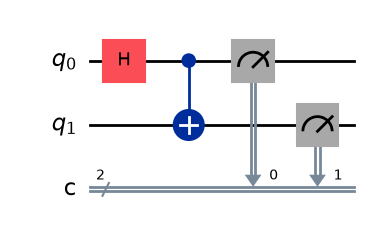

In [11]:
# Create Part A circuit
qc_a = QuantumCircuit(2, 2)

qc_a.h(0)
qc_a.cx(0, 1)

# Measure both qubits
qc_a.measure([0, 1], [0, 1])

print("Part A Circuit: Correlated Outcomes")
display(qc_a.draw("mpl"))

In [12]:
# Run Part A for 100 shots
compiled_a = transpile(qc_a, simulator)

result_a = simulator.run(
    compiled_a,
    shots=SHOTS
).result()

counts_a = result_a.get_counts()

print("Part A Measurement Counts:")
print(counts_a)
print("Total shots:", sum(counts_a.values()))

Part A Measurement Counts:
{'11': 57, '00': 43}
Total shots: 100


### Part A - Explanation

The outcomes 00 and 11 should dominate.

Both qubits have the same measurement value. The Hadamard and CNOT gates prepare an entangled Bell state.

In an ideal simulator, outcomes 01 and 10 should have zero counts.

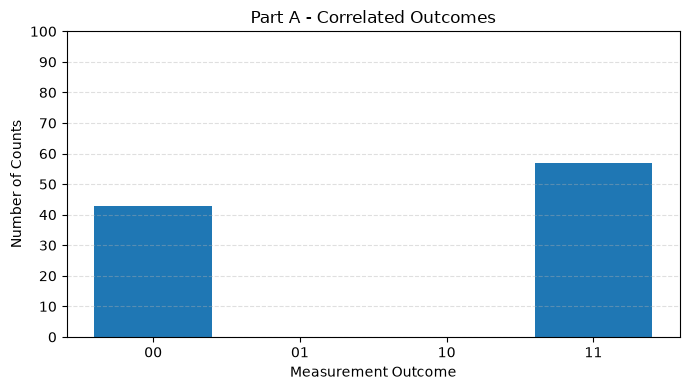

In [13]:
# Part A histogram
outcomes = ["00", "01", "10", "11"]
values_a = [counts_a.get(x, 0) for x in outcomes]

plt.figure(figsize=(7, 4))

plt.bar(outcomes, values_a)

plt.title("Part A - Correlated Outcomes")
plt.xlabel("Measurement Outcome")
plt.ylabel("Number of Counts")
plt.ylim(0, 100)
plt.yticks(range(0, 101, 10))
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 4. Part B - Opposite Outcomes

### Circuit Design

1. Apply a Hadamard gate to qubit 0.
2. Apply a Controlled-NOT gate.
3. Apply an X gate to qubit 1.
4. Measure both qubits.

The X gate flips the second qubit.

Expected dominant outcomes: 01 and 10.

Qubits: 2
Quantum gates before measurement: 3
Shots: 100

Part B Circuit: Opposite Outcomes


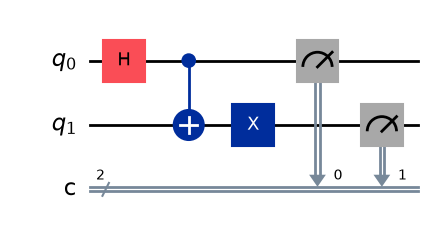

In [14]:
# Create Part B circuit
qc_b = QuantumCircuit(2, 2)

qc_b.h(0)
qc_b.cx(0, 1)
qc_b.x(1)

# Measure both qubits
qc_b.measure([0, 1], [0, 1])

print("Part B Circuit: Opposite Outcomes")
display(qc_b.draw("mpl"))

In [15]:
# Run Part B for 100 shots
compiled_b = transpile(qc_b, simulator)

result_b = simulator.run(
    compiled_b,
    shots=SHOTS
).result()

counts_b = result_b.get_counts()

print("Part B Measurement Counts:")
print(counts_b)
print("Total shots:", sum(counts_b.values()))

Part B Measurement Counts:
{'01': 45, '10': 55}
Total shots: 100


### Part B - Explanation

The outcomes 01 and 10 should dominate.

The X gate flips the second qubit, changing the equal measurement outcomes into opposite outcomes.

In an ideal simulator, outcomes 00 and 11 should have zero counts.

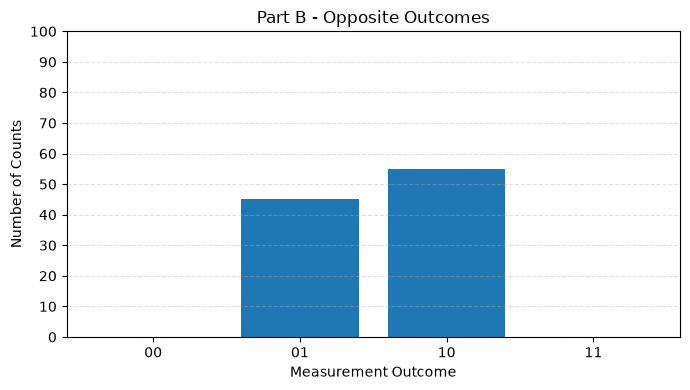

In [16]:
# Part B histogram
values_b = [counts_b.get(x, 0) for x in outcomes]

plt.figure(figsize=(7, 4))

plt.bar(outcomes, values_b)

plt.title("Part B - Opposite Outcomes")
plt.xlabel("Measurement Outcome")
plt.ylabel("Number of Counts")
plt.ylim(0, 100)
plt.yticks(range(0, 101, 10))
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 5. Part C - Combined Histogram Comparison

The following figure displays both experiments side by side.

Part A should show dominant counts for 00 and 11.

Part B should show dominant counts for 01 and 10.

Both experiments use 100 shots.

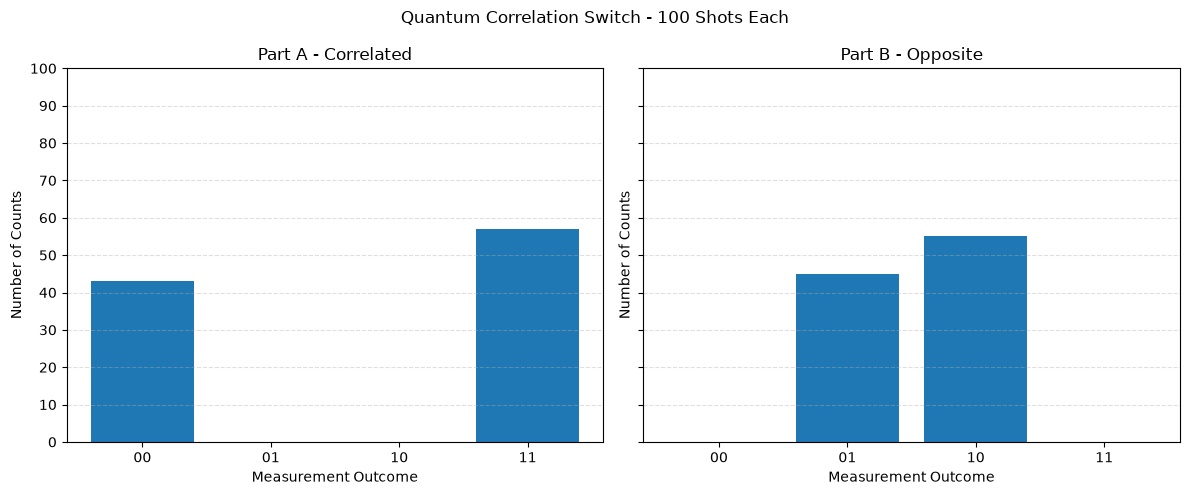

In [17]:
# Prepare counts for all outcomes
values_a = [counts_a.get(x, 0) for x in outcomes]
values_b = [counts_b.get(x, 0) for x in outcomes]

# Create two plots side by side
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True
)

# Combined figure: Part A
axes[0].bar(outcomes, values_a)
axes[0].set_title("Part A - Correlated")
axes[0].set_xlabel("Measurement Outcome")
axes[0].set_ylabel("Number of Counts")
axes[0].set_ylim(0, 100)
axes[0].set_yticks(range(0, 101, 10))
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# Combined figure: Part B
axes[1].bar(outcomes, values_b)
axes[1].set_title("Part B - Opposite")
axes[1].set_xlabel("Measurement Outcome")
axes[1].set_ylabel("Number of Counts")
axes[1].set_ylim(0, 100)
axes[1].set_yticks(range(0, 101, 10))
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

fig.suptitle("Quantum Correlation Switch - 100 Shots Each")

plt.tight_layout()
plt.show()

In [18]:
print("Outcome | Part A Counts | Part B Counts")
print("---------------------------------------")

for outcome in outcomes:
    print(
        f"{outcome:7} | "
        f"{counts_a.get(outcome, 0):13} | "
        f"{counts_b.get(outcome, 0):13}"
    )

print("\nTotal Part A shots:", sum(counts_a.values()))
print("Total Part B shots:", sum(counts_b.values()))

Outcome | Part A Counts | Part B Counts
---------------------------------------
00      |            43 |             0
01      |             0 |            45
10      |             0 |            55
11      |            57 |             0

Total Part A shots: 100
Total Part B shots: 100


## 6. Comparison and Discussion

### 1. Which outcomes are dominant in Part A?
The outcomes 00 and 11 are dominant because both qubits have the same measurement value.

### 2. Which outcomes are dominant in Part B?
The outcomes 01 and 10 are dominant because the X gate flips the second qubit.

### 3. What changed between the circuits?
Part A uses H and CX gates. Part B uses H, CX, and X gates.

### 4. Why did the measurement relationship change?
The X gate flips the second qubit, changing the equal outcomes 00 and 11 into opposite outcomes 01 and 10.

### 5. Will all four outcomes appear?
In an ideal simulator, only the expected two outcomes should appear. Each expected outcome should occur approximately 50 times in 100 shots.

### Conclusion
The experiment demonstrates that adding an X gate switches the measurement relationship from correlated outcomes to opposite outcomes.

## 7. Verification of Design Constraints

| Requirement | Part A | Part B |
|---|---|---|
| Number of qubits | 2 | 2 |
| Quantum gates before measurement | 2 | 3 |
| Both qubits measured | Yes | Yes |
| Number of shots | 100 | 100 |
| Expected dominant outcomes | 00, 11 | 01, 10 |
| Maximum 4 gates respected | Yes | Yes |

## 8. Final Submission Checklist

- Part A circuit diagram included.
- Part B circuit diagram included.
- Predictions for both experiments included.
- Part A measurement counts recorded.
- Part B measurement counts recorded.
- Part A separate histogram included.
- Part B separate histogram included.
- Combined side-by-side histograms included.
- Comparison table included.
- Dominant outcomes explained.
- Change in measurement relationship explained.
- Circuit design constraints verified.

## 9. Final Result

Part A produces correlated outcomes, mainly 00 and 11.

Part B produces opposite outcomes, mainly 01 and 10.

The additional X gate changes the measurement relationship between the two qubits.

The notebook demonstrates the Quantum Correlation Switch using two qubits and no more than four quantum gates before measurement.

**Note:** The results shown are from an ideal simulator. Exact counts depend on the sampling run, and real quantum hardware may produce additional outcomes due to noise.